# Assignment No. 2: Data Cleaning and Preprocessing

## 1. Dataset Description

**Dataset Title:** Titanic — Machine Learning from Disaster

**Source:** https://www.kaggle.com/competitions/titanic/data

**Objective:** The dataset contains information about Titanic passengers. The objective is to clean and preprocess the data and prepare it for a machine learning task that predicts passenger survival.

**Dataset Size:** 891 rows and 12 columns.

**Main Features:** PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, and Embarked.

**Target Variable:** Survived. A value of 0 means the passenger did not survive, while 1 means the passenger survived.

In [25]:

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
display(df.head())


Saving train.csv to train (1).csv
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [26]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Number of rows: 891
Number of columns: 12

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [27]:

missing_count = df.isnull().sum()

missing_percentage = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_table[missing_table["Missing Count"] > 0])


,Missing Count,Missing Percentage
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


### Interpretation of Missing Values

The dataset contains 177 missing values in Age (19.87%), 687 in Cabin (77.10%), and 2 in Embarked (0.22%). The missing Age values will be imputed using the median, while missing Embarked values will be filled using the mode. The original Cabin column will be excluded from the initial predictive feature set because most of its values are missing. These decisions reduce missing-data problems without inventing passenger information.

In [28]:

print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape after duplicate removal:", df.shape)


Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Dataset shape after duplicate removal: (891, 12)


### 3. Duplicate Record Detection

The dataset was checked for duplicate rows using the `duplicated()` function. Before cleaning, 0 duplicate rows were found. Therefore, no records were removed, and the dataset retained its original shape of 891 rows and 12 columns. Checking duplicates helps prevent repeated records from affecting data analysis.

In [5]:

print("Sex categories before cleaning:")
print(df["Sex"].unique())

print("\nEmbarked categories before cleaning:")
print(df["Embarked"].unique())

# Standardize text categories
for col in ["Sex", "Embarked"]:
    df[col] = df[col].apply(
        lambda x: x.strip().lower()
        if isinstance(x, str) else x
    )

print("\nSex categories after cleaning:")
print(df["Sex"].unique())

print("\nEmbarked categories after cleaning:")
print(df["Embarked"].unique())

print("\nData types:")
print(df.dtypes)


Sex categories before cleaning:
['male' 'female']

Embarked categories before cleaning:
['S' 'C' 'Q' nan]

Sex categories after cleaning:
['male' 'female']

Embarked categories after cleaning:
['s' 'c' 'q' nan]

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [6]:

print("Missing values before handling:")
print(df[["Age", "Embarked", "Cabin"]].isnull().sum())

# Fill missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with the mode
df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0]
)

print("\nMissing values after handling:")
print(df[["Age", "Embarked", "Cabin"]].isnull().sum())


Missing values before handling:
Age         177
Embarked      2
Cabin       687
dtype: int64

Missing values after handling:
Age           0
Embarked      0
Cabin       687
dtype: int64


### 4. Missing Value Handling

The dataset initially contained 177 missing values in Age, 687 in Cabin, and 2 in Embarked. Missing Age values were filled using the median because it is less sensitive to extreme values than the mean. Missing Embarked values were filled using the mode because it is a categorical variable. The original Cabin column was retained in the cleaned dataset for inspection but will be excluded from the initial predictive feature set due to its high percentage of missing values.

In [7]:

for col in ["Age", "Fare", "SibSp", "Parch"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print("\nColumn:", col)
    print("Lower limit:", round(lower, 2))
    print("Upper limit:", round(upper, 2))
    print("Potential outliers:", count)



Column: Age
Lower limit: 2.5
Upper limit: 54.5
Potential outliers: 66

Column: Fare
Lower limit: -26.72
Upper limit: 65.63
Potential outliers: 116

Column: SibSp
Lower limit: -1.5
Upper limit: 2.5
Potential outliers: 46

Column: Parch
Lower limit: 0.0
Upper limit: 0.0
Potential outliers: 213


### 5. Outlier Detection

Potential outliers were identified using the Interquartile Range (IQR) method. The method flagged 66 values in Age, 116 in Fare, 46 in SibSp, and 213 in Parch. However, these values may represent genuine passenger characteristics, such as older passengers, expensive tickets, or larger families. Therefore, the records were not automatically removed. The Parch feature has an IQR of zero, which causes all positive values to be flagged. This illustrates why outlier detection results must be interpreted carefully.

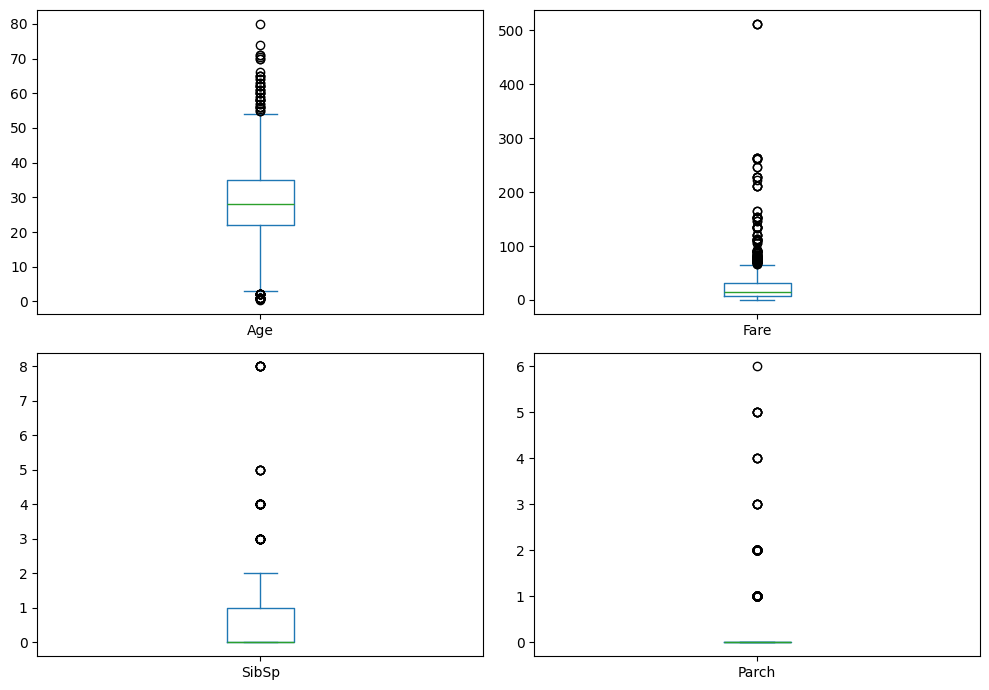

In [8]:

df[["Age", "Fare", "SibSp", "Parch"]].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 7),
    sharex=False
)

plt.tight_layout()
plt.show()


In [9]:

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

display(df[[
    "SibSp", "Parch", "FamilySize", "IsAlone"
]].head(10))


,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [10]:

display(df[[
    "PassengerId", "SibSp", "Parch",
    "FamilySize", "IsAlone"
]].head(10).to_string(index=False))


' PassengerId  SibSp  Parch  FamilySize  IsAlone\n           1      1      0           2        0\n           2      1      0           2        0\n           3      0      0           1        1\n           4      1      0           2        0\n           5      0      0           1        1\n           6      0      0           1        1\n           7      0      0           1        1\n           8      3      1           5        0\n           9      0      2           3        0\n          10      1      0           2        0'

Fare skewness: 4.787


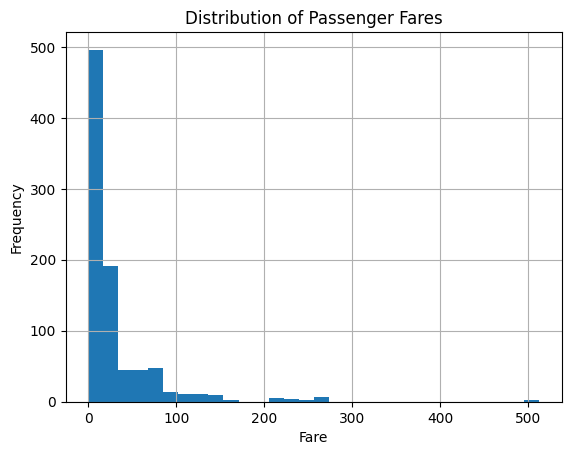

In [11]:

print("Fare skewness:", round(df["Fare"].skew(), 3))

df["Fare"].hist(bins=30)
plt.title("Distribution of Passenger Fares")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()


### 6. Skewness and Numerical Transformation

The Fare feature has a skewness value of 4.787, indicating a strongly right-skewed distribution. Most passengers paid relatively low fares, while a smaller number paid much higher fares. A logarithmic transformation using log1p is suitable for reducing this skewness. The transformation will be applied during preprocessing, and the original Fare values will be retained in the cleaned dataset.

In [12]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

# Separate features and target
X = df.drop(columns=[
    "Survived", "PassengerId", "Name", "Ticket", "Cabin"
])
y = df["Survived"]

# Identify feature types
numeric_features = [
    "Age", "SibSp", "Parch", "FamilySize", "IsAlone"
]
fare_features = ["Fare"]
categorical_features = ["Sex", "Embarked"]
ordinal_features = ["Pclass"]

print("Features:", X.columns.tolist())
print("\nTarget:", y.name)
print("\nFeature count:", len(X.columns))


Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']

Target: Survived

Feature count: 9


In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 712
Testing rows: 179


In [18]:

# Numerical features: fill missing values and standardize
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fare: fill missing values, reduce skewness, and standardize
fare_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("scaler", StandardScaler())
])

# Categorical features: fill missing values and encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Pclass: preserve its ordered numeric codes
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

print("All four preprocessing pipelines are defined.")


All four preprocessing pipelines are defined.


In [19]:

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("fare", fare_pipeline, fare_features),
    ("categorical", categorical_pipeline, categorical_features),
    ("ordinal", ordinal_pipeline, ordinal_features)
])

print("Preprocessor created successfully.")


Preprocessor created successfully.


In [20]:

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (712, 12)
Processed testing shape: (179, 12)


In [21]:
# Reload the original dataset so its missing values are restored
df = pd.read_csv("train.csv")

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Standardize categorical text
for col in ["Sex", "Embarked"]:
    df[col] = df[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

# Create new features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Separate features and target
X = df.drop(columns=[
    "Survived", "PassengerId", "Name", "Ticket", "Cabin"
])
y = df["Survived"]

# Split BEFORE imputing missing values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Missing Age values in training:", X_train["Age"].isna().sum())
print("Missing Embarked values in training:", X_train["Embarked"].isna().sum())

Training rows: 712
Testing rows: 179
Missing Age values in training: 137
Missing Embarked values in training: 2


In [22]:

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nMissing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())


Training data shape: (712, 9)
Testing data shape: (179, 9)

Missing values in training data:
Pclass          0
Sex             0
Age           137
SibSp           0
Parch           0
Fare            0
Embarked        2
FamilySize      0
IsAlone         0
dtype: int64

Missing values in testing data:
Pclass         0
Sex            0
Age           40
SibSp          0
Parch          0
Fare           0
Embarked       0
FamilySize     0
IsAlone        0
dtype: int64


In [23]:

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
print("Preprocessing completed successfully!")


Training data after preprocessing: (712, 12)
Testing data after preprocessing: (179, 12)
Preprocessing completed successfully!


In [24]:

import numpy as np

print("Missing values in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing data:",
      np.isnan(X_test_processed).sum())

print("All training values finite:",
      np.isfinite(X_train_processed).all())

print("All testing values finite:",
      np.isfinite(X_test_processed).all())


Missing values in training data: 0
Missing values in testing data: 0
All training values finite: True
All testing values finite: True


## 13. Conclusion

The Titanic dataset was inspected and cleaned by checking missing values, duplicate records, categorical consistency, data types, and potential outliers. Missing values were handled using suitable imputation strategies. The `FamilySize` and `IsAlone` features were created to add useful information.

A preprocessing pipeline was developed to perform encoding, imputation, logarithmic transformation, and standardization. The data was split into training and testing sets before the preprocessing pipeline was fitted. Final verification confirmed that the processed training and testing datasets contained no missing or non-finite numerical values.

The resulting data is ready for further analysis or machine-learning model development.